This notebook analysis the performance of the classifier in terms of response speed: i.e. how fast can the module identify a TDE with respect to its first observation and its peak.


In [2]:
from early_tde_classification.config import Config
import os
import pandas as pd
from astropy.table import Table

## 1. Load data

Let's load the lightcurves of the TDEs

In [3]:
from early_tde_classification.extract_features import load_extragalatic_data_full_lightcurves as load_lcs
Config.EXTRAGAL_FNAME = 'tde_objects_all_withupperlim_min5_1.parquet'

all_lcs = load_lcs()
print(len(all_lcs), 'light curves')

# all_lcs = pd.read_parquet('/home/lmiguel/gitlab_projects/TDE classification/tde_classification/data/input/tde_objects_all_withupperlim_min5_1.parquet')

print(len(all_lcs), 'light curves')

603216 light curves
603216 light curves


Let's get TNS indices.

In [4]:
import io
import requests

r = requests.post(
    'https://api.fink-portal.org/api/v1/resolver',
    json={
        'resolver': 'tns',
        'name': '',
        'nmax': 1000000
    }
)
tns = pd.read_json(io.BytesIO(r.content))
print(len(tns), 'TNS entries')

tns_tdes = tns[[_.startswith('TDE') and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_tdes = list(tns_tdes['d:internalname'].drop_duplicates().values.astype(str))
print(len(tns_tdes), 'TDEs')

tns_nontdes = tns[[not _.startswith('TDE') and _ != 'nan' and __.startswith('ZTF') for _,__ in zip(tns['d:type'], tns['d:internalname'])]]
tns_nontdes = list(tns_nontdes['d:internalname'].drop_duplicates().values.astype(str))
print(len(tns_nontdes), 'non-TDEs')

240026 TNS entries
110 TDEs
13021 non-TDEs


In [5]:
tns_types = tns[['d:internalname', 'd:fullname', 'd:type']]
tns_types = tns_types[[_.startswith('ZTF') for _ in tns_types['d:internalname'].values]]
tns_types.rename(columns={'d:internalname': 'objectId', 'd:fullname': 'tns_name', 'd:type': 'tns'}, inplace=True)
tns_types = tns_types.drop_duplicates('objectId')

In [6]:
all_lcs.columns

Index(['objectId', 'candid', 'v:classification', 'd:cdsxmatch', 'ra', 'dec',
       'classtar', 'distnr', 'maggaia', 'neargaia', 'maggaiabright',
       'neargaiabright', 'jdstarthist', 'fid', 'jd', 'magpsf', 'sigmapsf',
       'sdiffpos', 'diffmaglim', 'b', 'FLUXCAL', 'FLUXCALERR', 'type'],
      dtype='object')

In [7]:
# More robust, positional association, as often we do not have ZTF name listed there...
all_lcs = all_lcs.join(tns_types.set_index('objectId'), on='objectId')
from stdpipe import astrometry # TODO: directly embed the function here

# ids1,ids2,dist = astrometry.spherical_match(tns['d:ra'], tns['d:declination'], all_lcs['i:ra'], all_lcs['i:dec'], 5/3600)
ids1,ids2,dist = astrometry.spherical_match(tns['d:ra'], tns['d:declination'], all_lcs['ra'], all_lcs['dec'], 5/3600)


# TODO: fix that stupid pandas warning
all_lcs['tns_name'][ids2] = tns['d:fullname'][ids1]
all_lcs['tns'][ids2] = tns['d:type'][ids1]

/home/lmiguel/anaconda3/envs/tdes/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_33868/91431822.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_lcs['tns_name'][ids2] = tns['d:fullname'][ids1]
/tmp/ipykernel_33868/91431822.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_lcs['tns'][ids2] = tns['d:type'][ids1]


In [8]:
tns_tdes = list(set(tns_tdes) | set(all_lcs['objectId'][[_.startswith('TDE') for _ in all_lcs['tns'].values.astype(str)]]))
print(len(tns_tdes), 'TDEs')

idx = all_lcs['tns'].astype(str) != 'nan'
idx &= [not _.startswith('TDE') for _ in all_lcs['tns'].values.astype(str)]
tns_nontdes = list(set(tns_nontdes) | set(all_lcs['objectId'][idx]))
print(len(tns_nontdes), 'non-TDEs')

idx = all_lcs['tns_name'].astype(str) != 'nan'
tns_all = list(set(all_lcs['objectId'][idx]))
print(len(tns_all), 'total TNS')

116 TDEs
13446 non-TDEs
31317 total TNS


/tmp/ipykernel_33868/1847501210.py:5: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.
  idx &= [not _.startswith('TDE') for _ in all_lcs['tns'].values.astype(str)]


In [9]:
maybe_tdes = ['ZTF24aamfius', 'ZTF25aagfhmz', 'ZTF25aaknwwy', 'ZTF25aagrecw', 'ZTF20abjwvae']
additional_tdes = ['ZTF18aabtxvd', 'ZTF18actaqdw', 'ZTF18acnbpmd', 'ZTF19aakiwze', 'ZTF19abhejal', 'ZTF19abhhjcc', 'ZTF20aamqmfk', 'ZTF18aakelin', 'ZTF20abjwvae', 'ZTF20abefeab', 'ZTF20abowque', 'ZTF20abrnwfc', 'ZTF20abnorit']
ant_tdes = ['ZTF22aadesap', 'ZTF21abxowzx', 'ZTF20acvfraq', 'ZTF20abgxlut']

And let's load the features

In [10]:
def post_fit_filtering(features):
    
    good_idx = features['r_chisq'] < 10    
    good_idx &= features['num_hist_detections'] < 1 # No detections in 100 days prior to the window
    good_idx &= features['num_prehist_negatives'] <= 1 # No negatives prior to the window
    
    good_idx &= features['e_reference_time'] < 100
    good_idx &= features['norm_rel_reference_time'] < 0 # 10
    good_idx &= features['norm_rel_reference_time'] > -10
    
    good_idx &= features['snr_rise_time'] > 1.5
    good_idx &= features['snr_T'] > 1.5
    
    # good0_idx = good_idx.copy()
    # good_idx &= features['pcounter'] == 0 # Only last sets of features for every peak

    features = features[good_idx]
    return features
    
feat_data = Table.read(os.path.join(Config.OUT_FEATURES_DIR, 'features_sergey_2025', 'features.all.pmulti.distnr.vot')).to_pandas()

print('Alerts with extracted features',len(feat_data))
print('Objects with extracted features',len(feat_data[feat_data['pcounter']==0]))


# Filter 
feat_data = post_fit_filtering(feat_data)

# Get indices
# tns_idx = np.isin(feat_data['objectId'], tns_nontdes + tns_tdes) # Everything in TNS

tns_all_idx = np.isin(feat_data['objectId'], tns_all) # all in TNS
# tde_idx = np.isin(feat_data['objectId'], tns_tdes + maybe_tdes + additional_tdes) # TDEs in TNS
# sn_idx = np.array([_.startswith('SN') for _ in feat_data['tns']]) # SNe in TNS

# Get only those with a TNS label
feat_data = feat_data[tns_all_idx]

feat_data = feat_data[feat_data['pcounter'] == 0] # Only last sets of features for every peak

print("objects after post-fit cuts",len(feat_data))

Alerts with extracted features 349104
Objects with extracted features 80997
objects after post-fit cuts 8864


In [11]:
feat_data = Table.read(os.path.join(Config.OUT_FEATURES_DIR, 'features_sergey_2025', 'features.all.pmulti.distnr.vot')).to_pandas()


In [12]:
feat_data.norm_rel_reference_time

0         -1.950847
1          2.428865
2        -78.047718
3        -77.976737
4          0.786011
            ...    
349099    -1.850541
349100    -1.910620
349101    -1.079362
349102    -1.372392
349103    -0.511872
Name: norm_rel_reference_time, Length: 349104, dtype: float64

## 2. Get RMS fractional variability




In [74]:
# for index, row_feat in feat_data.iterrows():
def get_rms_frac(row_feat, all_lcs): 
    obj_lc = all_lcs[all_lcs.objectId == row_feat.objectId].iloc[0]
    mask_no_upper_limits = np.isfinite(obj_lc.FLUXCAL)
        
    # Define hist LC
    hist_lc_mask = obj_lc.jd < row_feat.jd_min
    hist_lc_fluxes = obj_lc.FLUXCAL[hist_lc_mask & mask_no_upper_limits]
    hist_lc_fluxes = obj_lc.FLUXCAL[mask_no_upper_limits]

    # Get max flux from fitting window
    max_flux = np.max(obj_lc.FLUXCAL[mask_no_upper_limits & ~hist_lc_mask])

    if len(hist_lc_fluxes) > 1:
        
        # Compute RMS fractional variability wrt to peak flux
        rms = np.sqrt(np.mean(hist_lc_fluxes**2))
        rms_frac = rms / max_flux
        print(rms_frac)
        
    else:
        rms_frac = 0
    return rms_frac

feat_data['rms'] = feat_data.apply(lambda x: get_rms_frac(x, all_lcs), axis = 1)

0.5595064929275305
0.8232085958770089
0.5290933736603877
0.4746672255396522
0.65611579678441
0.5064368961305584
0.3891033460438951
0.5031217126161267
0.3865552203619242
0.5899963974261956
0.6682184428081868
0.7740258419698359
0.6613271253056638
0.5279208238352993
0.3475253055628915
0.4150565883978566
0.1538750114288615
0.5143479889254019
0.6186770525444835
0.6663777093020117
0.653580968118162
2.295881742678931
0.7292650624374793
0.5227499135665677
0.7525119654639417
0.7509774018496519
0.5858551267959836
0.6487127086091727
0.6461559375174577
0.6615399917754827
0.6001747655265997
0.4392782204469533
0.7791685194757608
0.5423641239914987
0.3806978265271327
0.7433931168243741
0.510110013786988
0.8454630042344704
0.5938668438127593
0.5074363492428535
0.40538611817548065
0.6165803353916407
0.5610410489269623
0.29811023244294416
0.4966597958352672
0.6407237702208052
0.5797510158302536
0.5740424321363393
0.33654827911617397
0.3832907864575235
0.5730380899301601
0.49755411311120523
0.68119302744

In [75]:
def classify_broad(entry):
    entry = str(entry).upper()
    if 'SN' in entry:
        return 'SN'
    elif 'AGN' in entry or 'QSO' in entry or 'Galaxy' in entry:
        return 'QSO'
    elif 'TDE' in entry:
        return 'TDE'
    else:
        return 'Other'

feat_data['class_tns'] = feat_data['tns'].apply(classify_broad)

In [76]:
feat_data.class_tns.unique()
feat_data.groupby('class_tns').size()

class_tns
Other    4855
QSO        16
SN       3956
TDE        37
dtype: int64

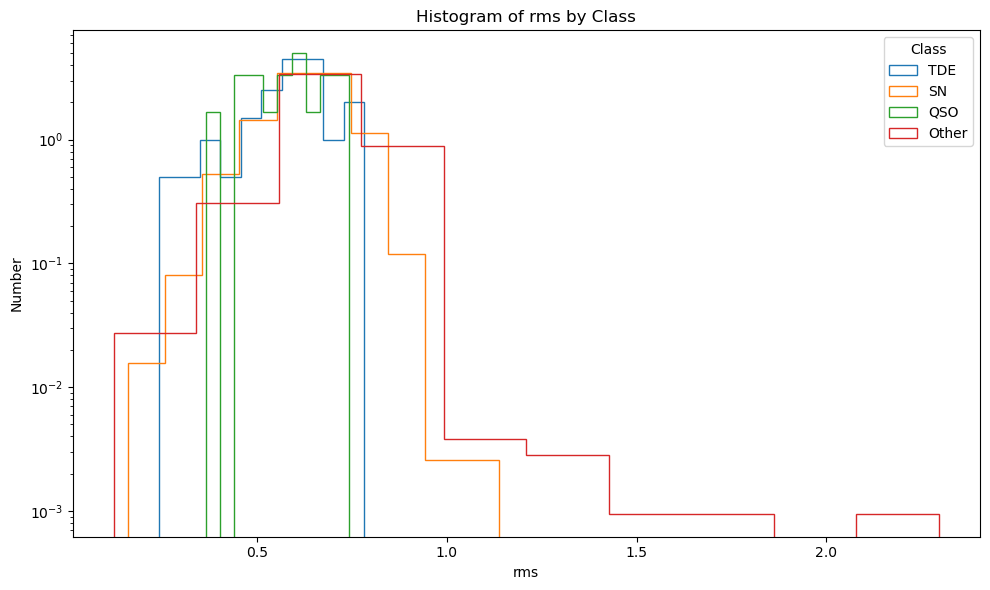

In [81]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter only relevant classes
classes_to_plot = ['TDE', 'SN', 'QSO', 'Other']
# classes_to_plot = ['TDE', 'SN', 'QSO']

filtered_df = feat_data[feat_data['class_tns'].isin(classes_to_plot)].copy()
# filtered_df = filtered_df[filtered_df.rms!=0]

# Ensure 'class' is a category to help with plotting
filtered_df['class_tns'] = filtered_df['class_tns'].astype('category')
# Plot
plt.figure(figsize=(10, 6))

# Plot one histogram per class
bins = np.linspace(filtered_df['rms'].min(), filtered_df['rms'].max(), 30)
for cls in classes_to_plot:
    subset = filtered_df[filtered_df['class_tns'] == cls]
    
    plt.hist(subset['rms'], bins=10, histtype='step', label=cls, density = True)

plt.yscale('log')
plt.xlabel('rms')
# plt.ylabel('Density')
plt.ylabel('Number')

plt.title('Histogram of rms by Class')
plt.legend(title='Class')
plt.tight_layout()
plt.show()


Unknown
0
QSO
16
SN
3956
TDE
37


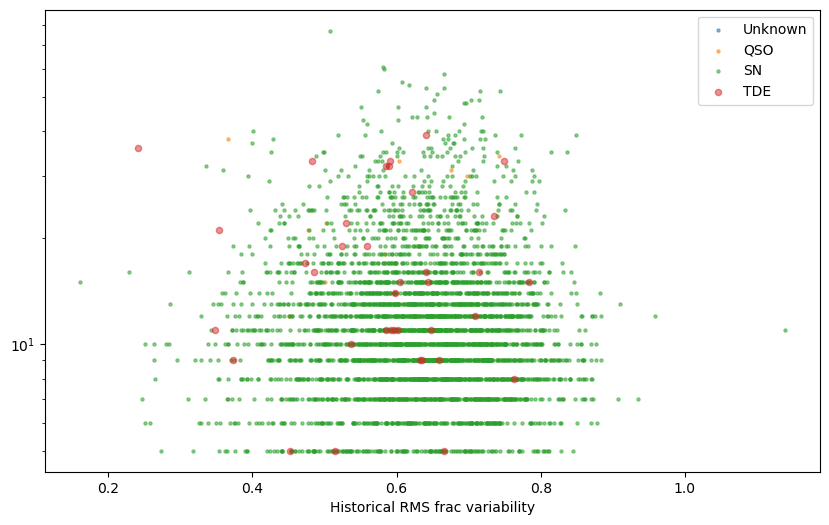

In [86]:
import matplotlib.pyplot as plt


# Filter only relevant classes
classes_to_plot = ['TDE', 'SN', 'QSO', 'Other']
classes_to_plot = ['Unknown', 'QSO', 'SN', 'TDE']
sizes_plot = [5, 5, 5, 20]
# classes_to_plot = ['TDE', 'SN', 'QSO']

filtered_df = feat_data[feat_data['class_tns'].isin(classes_to_plot)].copy()
# filtered_df = filtered_df[filtered_df.rms!=0]

# Plot
plt.figure(figsize=(10, 6))

# Plot one histogram per class
for cls, size in zip(classes_to_plot, sizes_plot):
    subset = filtered_df[filtered_df['class_tns'] == cls]
    print(cls)
    print(len(subset))
    
    plt.scatter(subset['rms'], subset['num_detections'], label = cls, alpha = 0.5, s = size)

plt.xlabel('Historical RMS frac variability')
# plt.xscale('log')
plt.yscale('log')

plt.legend()


